# 04 · Backtesting : ce que vaut le design quand on connaît la vérité

Un intervalle à 95 % n'a de sens que s'il contient la vérité 95 % du temps. Sur les vraies campagnes, la vérité
est inconnue ; on la **plante** : un effet connu (0 %, 5 %, 15 %, 30 % ; marche, rampe, impulsion ; avec
*pull-forward* ; avec cannibalisation d'un donneur) écrit dans des fenêtres calmes de vraies séries du panel,
avec le vrai registre de donneurs. Chaque estimateur est noté par sa couverture, son biais, sa puissance et la
largeur de ses intervalles. L'effet nul donne le taux de faux positifs du design sur des séries jamais traitées,
la référence contre laquelle lire les placebos des vraies campagnes. Les chiffres viennent de `nr backtest`
(`data/results/planted.parquet`) et de `nr estimate`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from novaretail import viz
from novaretail.backtest import PlantSpec, plant, quiet_windows
from novaretail.data import RESULTS
from novaretail.workspace import load_world

viz.setup()
export = viz.exporter("../figures")
study = pd.read_parquet(RESULTS / "planted.parquet")
scores = pd.read_parquet(RESULTS / "planted_scores.parquet")
est = pd.read_parquet(RESULTS / "estimates.parquet")
est_rep = json.loads((RESULTS / "estimates.json").read_text())
ORDER = ["bsts_llevel", "bsts_static", "ols", "augmented_sc", "synthetic_control", "diff_in_diff"]
n_per_spec = int(study.groupby("spec")["plant"].nunique().median())
print(f"{study['plant'].nunique()} fenêtres plantées par spécification en médiane : {n_per_spec} ; "
      f"{study['estimator'].nunique()} estimateurs ; {int(study['error'].notna().sum())} ajustements en erreur")

6 fenêtres plantées par spécification en médiane : 6 ; 6 estimateurs ; 0 ajustements en erreur


## 1. Une vérité plantée, à quoi ça ressemble

**Exemple.** Une fenêtre calme d'une vraie série (aucune campagne de 150 jours avant à 21 jours après), un
effet multiplicatif de +15 % pendant sept jours, puis un creux qui rend la moitié des unités gagnées sur
quatorze jours. La série modifiée est ce que l'estimateur voit ; la série d'origine est le contrefactuel exact.

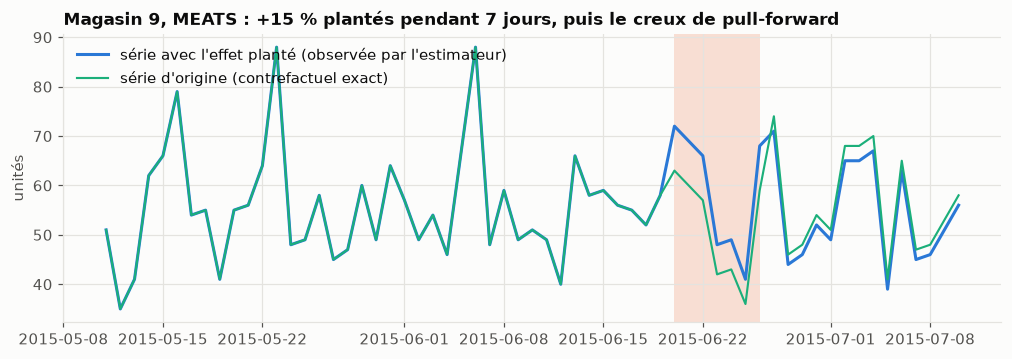

effet cumulé vrai sur l'échelle log : +0.368


In [2]:
w = load_world()
spec = PlantSpec(rel_lift=0.15, pull_forward=0.5)
win = quiet_windows(w.wide_raw, w.wide_promo, w.usable, spec, n=1, seed=3)[0]
unit = (win["store_nbr"], win["family"])
planted, truth = plant(w.wide_raw, win, spec, [])
sl = slice(win["start"] - pd.Timedelta(40, unit="D"), win["post_end"])
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(planted.loc[sl, unit], color=viz.BLUE, label="série avec l'effet planté (observée par l'estimateur)")
ax.plot(w.wide_raw.loc[sl, unit], color=viz.AQUA, linewidth=1.4, label="série d'origine (contrefactuel exact)")
ax.axvspan(win["start"], win["end"], color=viz.ORANGE, alpha=0.2, linewidth=0)
ax.set_title(f"Magasin {unit[0]}, {unit[1]} : +15 % plantés pendant 7 jours, puis le creux de pull-forward")
ax.set_ylabel("unités")
ax.legend(loc="upper left")
export(fig, "nb04_planted_example")
plt.show()
print(f"effet cumulé vrai sur l'échelle log : {truth['true_cum_log']:+.3f}")

## 2. Couverture des intervalles à 95 %

**Intuition.** C'est la seule note qui compte. Un estimateur trop confiant (intervalles étroits, couverture
basse) donne des « effets significatifs » partout, y compris là où il n'y a rien. La figure lit la couverture
sur la marche de +15 %, puis la met en regard de la largeur médiane des intervalles.

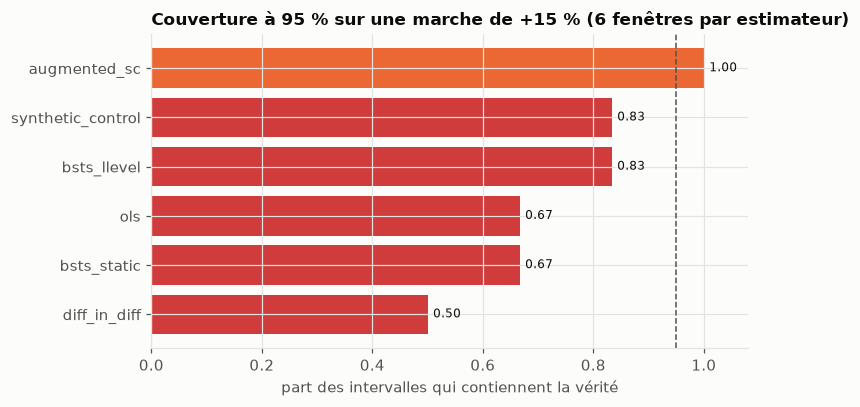

In [3]:
base = scores[(scores["shape"] == "step") & (scores["pull_forward"] == 0) & (scores["cannibal_share"] == 0)]
s15 = base[base["rel_lift"] == 0.15].set_index("estimator").reindex(ORDER)
fig, ax = viz.plot_coverage(s15[["coverage"]].assign(width_rel=s15["width"]),
                            f"Couverture à 95 % sur une marche de +15 % ({n_per_spec} fenêtres par estimateur)")
export(fig, "nb04_coverage")
plt.show()

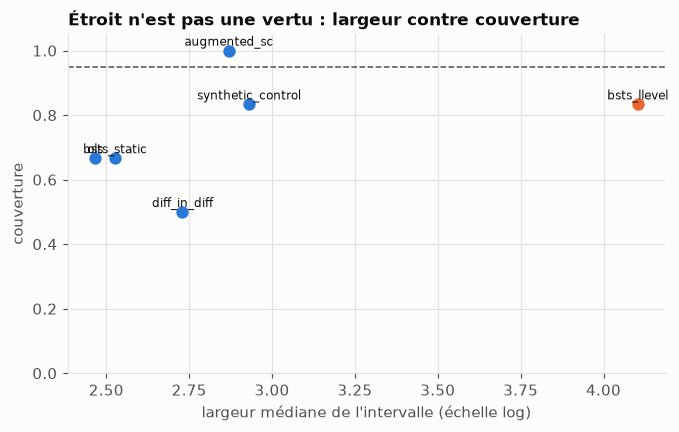

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, row in s15.iterrows():
    c = viz.ORANGE if name == "bsts_llevel" else viz.BLUE
    ax.scatter(row["width"], row["coverage"], color=c, s=50, zorder=3)
    ax.text(row["width"], row["coverage"] + 0.015, name, fontsize=8, ha="center")
ax.axhline(0.95, color=viz.TEXT_2, linestyle="--", linewidth=1)
ax.set_xlabel("largeur médiane de l'intervalle (échelle log)")
ax.set_ylabel("couverture")
ax.set_ylim(0, 1.05)
ax.set_title("Étroit n'est pas une vertu : largeur contre couverture")
export(fig, "nb04_width_vs_coverage")
plt.show()

## 3. Effet nul : le taux de faux positifs du design

**Attention.** À effet nul, la part des intervalles qui excluent zéro est le taux de faux positifs. Le
nominal est 5 %. Ce taux, mesuré sur des séries jamais traitées, est la référence pour lire le placebo dans le
temps des vraies campagnes : un placebo qui se déclenche une fois sur huit n'est pas une anomalie si le design
se déclenche une fois sur huit sur du vide.

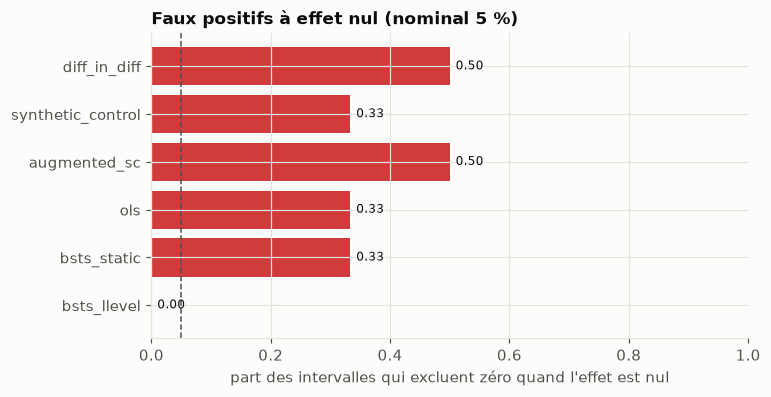

In [5]:
s0 = base[base["rel_lift"] == 0.0].set_index("estimator").reindex(ORDER)
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = [viz.GOOD if p <= 0.10 else (viz.ORANGE if p <= 0.3 else viz.CRITICAL) for p in s0["power"]]
ax.barh(s0.index, s0["power"], color=colors)
ax.axvline(0.05, color=viz.TEXT_2, linestyle="--", linewidth=1)
for i, v in enumerate(s0["power"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel("part des intervalles qui excluent zéro quand l'effet est nul")
ax.set_title("Faux positifs à effet nul (nominal 5 %)")
export(fig, "nb04_false_positives")
plt.show()

## 4. Puissance selon la taille de l'effet

**Exemple.** La part des intervalles qui excluent zéro quand l'effet existe, pour 5 %, 15 % et 30 % de lift
sur sept jours. Lire la puissance **avec** le taux de faux positifs : un estimateur qui détecte 90 % des
effets de 5 % mais se déclenche 60 % du temps sur du vide ne détecte rien.

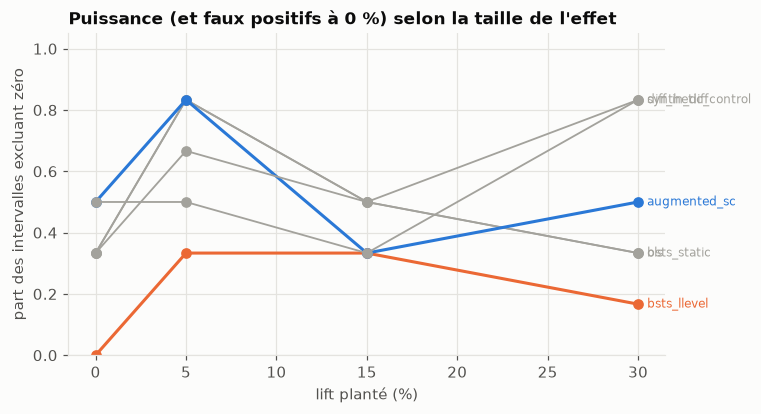

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for name in ORDER:
    s = base[base["estimator"] == name].sort_values("rel_lift")
    c = viz.ORANGE if name == "bsts_llevel" else (viz.BLUE if name == "augmented_sc" else viz.MUTED)
    ax.plot(s["rel_lift"] * 100, s["power"], marker="o", color=c, linewidth=2 if c != viz.MUTED else 1.2)
    ax.text(s["rel_lift"].iloc[-1] * 100 + 0.5, s["power"].iloc[-1], name, fontsize=8, va="center", color=c)
ax.set_xlabel("lift planté (%)")
ax.set_ylabel("part des intervalles excluant zéro")
ax.set_ylim(0, 1.05)
ax.set_title("Puissance (et faux positifs à 0 %) selon la taille de l'effet")
export(fig, "nb04_power")
plt.show()

## 5. Formes d'intervention, pull-forward, cannibalisation

**Intuition.** La marche est la forme la plus facile. Une rampe (l'effet monte au fil de la campagne), une
impulsion (pic puis décroissance), un creux de *pull-forward* après la fenêtre, et surtout une cannibalisation
(la moitié du lift pris sur le premier donneur du pool) sont les cas réels. La cannibalisation viole SUTVA :
aucun placebo dans le temps ne la voit, et le biais attendu est positif (le donneur baisse, le contrefactuel
baisse, l'effet apparent monte).

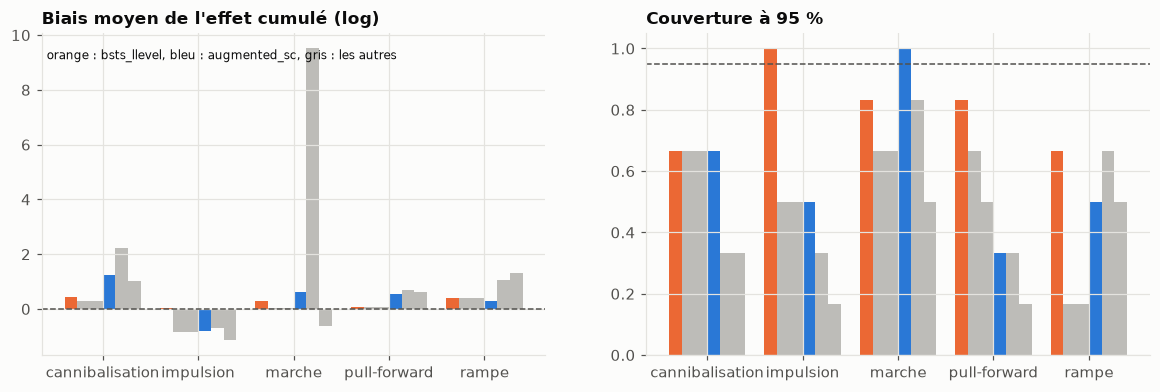

In [7]:
cases = scores[scores["rel_lift"] == 0.15].copy()
cases["cas"] = np.select([cases["cannibal_share"] > 0, cases["pull_forward"] > 0, cases["shape"] == "ramp",
                          cases["shape"] == "pulse"], ["cannibalisation", "pull-forward", "rampe", "impulsion"],
                         default="marche")
piv_b = cases.pivot_table(index="cas", columns="estimator", values="bias").reindex(columns=ORDER)
piv_c = cases.pivot_table(index="cas", columns="estimator", values="coverage").reindex(columns=ORDER)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, piv, title in ((axes[0], piv_b, "Biais moyen de l'effet cumulé (log)"),
                       (axes[1], piv_c, "Couverture à 95 %")):
    x = np.arange(len(piv))
    wd = 0.8 / len(ORDER)
    for j, name in enumerate(ORDER):
        c = viz.ORANGE if name == "bsts_llevel" else (viz.BLUE if name == "augmented_sc" else viz.MUTED)
        ax.bar(x + j * wd - 0.4 + wd / 2, piv[name], width=wd, color=c, alpha=1 if c != viz.MUTED else 0.7)
    ax.set_xticks(x, piv.index)
    ax.set_title(title)
    ax.axhline(0.95 if "Couverture" in title else 0, color=viz.TEXT_2, linewidth=1, linestyle="--")
axes[0].text(0.01, 0.95, "orange : bsts_llevel, bleu : augmented_sc, gris : les autres", transform=axes[0].transAxes,
             fontsize=8, va="top")
export(fig, "nb04_cases")
plt.show()

## 6. Retour sur les vraies campagnes

**Exemple.** Avec le taux de faux positifs mesuré, on relit les vraies campagnes : combien passent le
protocole, quel contrôle les élimine, et comment se distribuent leurs effets. La part des campagnes dont la
borne basse de l'effet net est positive est le chiffre que la direction attend ; celle dont la borne haute est
négative est le chiffre qu'elle redoute.

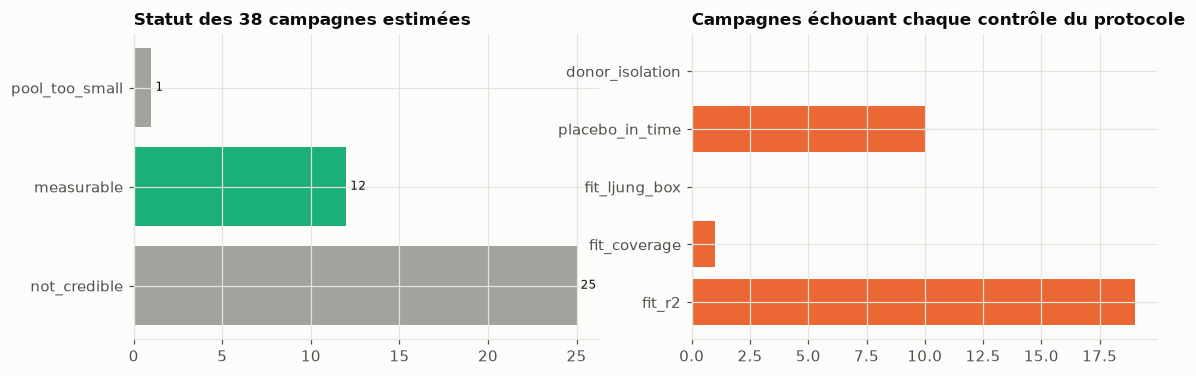

In [8]:
run = est[est["status"] != "pool_too_small"]
checks = pd.Series(est_rep["checks_failed"]).rename(lambda s: s.replace("check_", ""))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
st = est["status"].value_counts()
ax.barh(st.index, st.values, color=[viz.AQUA if s == "measurable" else viz.MUTED for s in st.index])
for i, v in enumerate(st.values):
    ax.text(v, i, f" {v}", va="center", fontsize=8)
ax.set_title(f"Statut des {len(est)} campagnes estimées")
ax = axes[1]
ax.barh(checks.index, checks.values, color=viz.ORANGE)
ax.set_title("Campagnes échouant chaque contrôle du protocole")
export(fig, "nb04_verdicts")
plt.show()

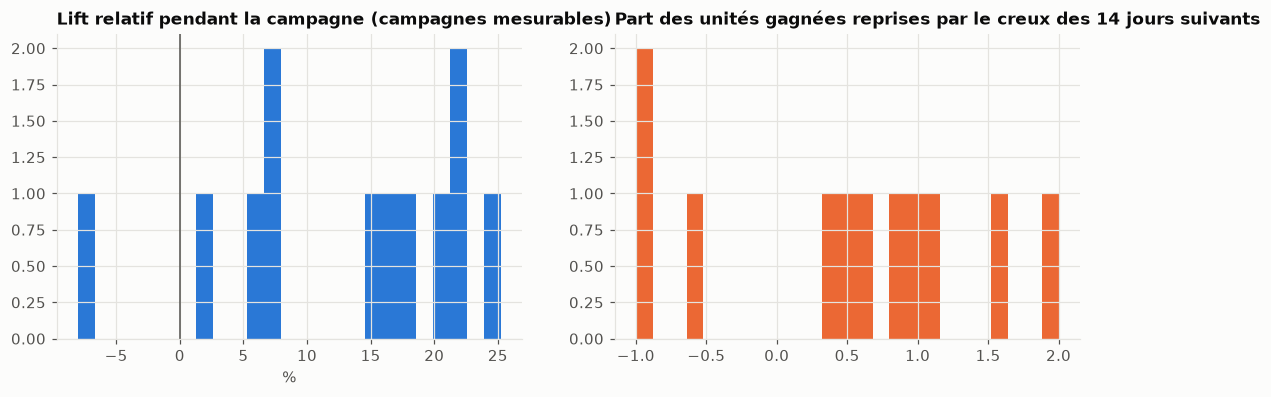

mesurables : 12 ; borne basse du net > 0 : 17% ; borne haute du net < 0 : 0% ; pull-forward médian : 61%


In [9]:
meas = est[est["status"] == "measurable"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
ax.hist(meas["during_rel"] * 100, bins=25, color=viz.BLUE)
ax.axvline(0, color=viz.TEXT_2, linewidth=1)
ax.set_title("Lift relatif pendant la campagne (campagnes mesurables)")
ax.set_xlabel("%")
ax = axes[1]
ax.hist(meas["pull_forward_share"].clip(-1, 2), bins=25, color=viz.ORANGE)
ax.set_title("Part des unités gagnées reprises par le creux des 14 jours suivants")
export(fig, "nb04_lift_distribution")
plt.show()
print(f"mesurables : {len(meas)} ; borne basse du net > 0 : {est_rep['share_net_lower_above_zero']:.0%} ; "
      f"borne haute du net < 0 : {est_rep['share_net_upper_below_zero']:.0%} ; "
      f"pull-forward médian : {est_rep['pull_forward_share_median']:.0%}")

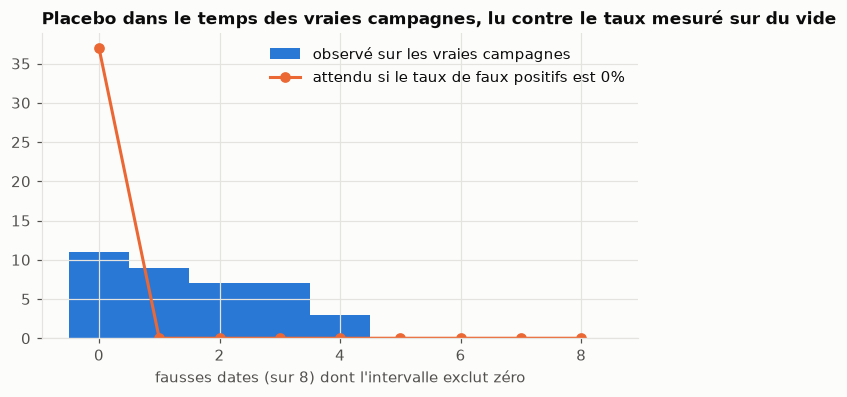

In [10]:
pt = pd.read_parquet(RESULTS / "placebo_time.parquet")
firing = pt.groupby("campaign_id")["excludes_zero"].agg(["sum", "size"])
fpr0 = float(s0.loc["bsts_llevel", "power"])
k = np.arange(0, 9)
from scipy import stats

expected = stats.binom.pmf(k, 8, fpr0) * len(firing)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(firing["sum"], bins=np.arange(-0.5, 9.5, 1), color=viz.BLUE, label="observé sur les vraies campagnes")
ax.plot(k, expected, marker="o", color=viz.ORANGE, label=f"attendu si le taux de faux positifs est {fpr0:.0%}")
ax.set_xlabel("fausses dates (sur 8) dont l'intervalle exclut zéro")
ax.set_title("Placebo dans le temps des vraies campagnes, lu contre le taux mesuré sur du vide")
ax.legend(loc="upper right")
export(fig, "nb04_placebo_vs_fpr")
plt.show()

## À retenir

- La couverture est la note ; la largeur est un choix de modèle. Les estimateurs à erreurs iid sont trop
  confiants sur des séries journalières autocorrélées, comme la veille l'avait mesuré.
- Le taux de faux positifs sur du vide est la référence du placebo dans le temps, pas 5 %.
- La cannibalisation d'un donneur biaise vers le haut sans que le placebo dans le temps bouge ; seul le
  registre (prévention) et l'isolation (détection) y répondent.
- **Recul sincère** : le nombre de fenêtres par spécification est petit ; les couvertures ont elles-mêmes une
  incertitude de l'ordre de ±0,1. Lire les ordres de grandeur, pas la deuxième décimale.